# Flight Fare Analytics: Booking Horizons and Fare Dynamics
**Group Prompters**, CSE558 Data Science midterm project.

Run all cells top to bottom (Kernel → Restart & Run All). Dataset: [Kaggle Flight Price Prediction](https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
df=pd.read_csv("Clean_Dataset.csv")
print(df.head())

   Unnamed: 0   airline   flight source_city departure_time stops  \
0           0  SpiceJet  SG-8709       Delhi        Evening  zero   
1           1  SpiceJet  SG-8157       Delhi  Early_Morning  zero   
2           2   AirAsia   I5-764       Delhi  Early_Morning  zero   
3           3   Vistara   UK-995       Delhi        Morning  zero   
4           4   Vistara   UK-963       Delhi        Morning  zero   

    arrival_time destination_city    class  duration  days_left  price  
0          Night           Mumbai  Economy      2.17          1   5953  
1        Morning           Mumbai  Economy      2.33          1   5953  
2  Early_Morning           Mumbai  Economy      2.17          1   5956  
3      Afternoon           Mumbai  Economy      2.25          1   5955  
4        Morning           Mumbai  Economy      2.33          1   5955  


## 1. Load, clean (index, missing values, duplicates) and profile the data

In [2]:
import pandas as pd
import numpy as np

# Print initial status
print("=== STEP 1: INITIAL DATA LOAD & CLEANING ===")
print(f"Initial row count: {len(df)}")
print(f"Initial column count: {df.shape[1]}")

# 1. Drop unnamed index column if present
if df.columns[0] == "" or "Unnamed" in str(df.columns[0]):
    df = df.iloc[:, 1:]
    print("-> Removed redundant index column.")

# 2. Check and handle missing values
missing_before = df.isnull().sum().sum()
print(f"Total missing values found: {missing_before}")
if missing_before > 0:
    df.dropna(inplace=True)
    print(f"-> Dropped rows with missing values. New row count: {len(df)}")
else:
    print("-> No missing values detected.")

# 3. Check and remove duplicate rows
duplicates = df.duplicated().sum()
print(f"Total duplicate rows found: {duplicates}")
if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print(f"-> Removed duplicates. Final clean row count: {len(df)}")
else:
    print("-> No duplicate rows detected.")

print("\n" + "="*50)
print("=== STEP 2: COLUMN METRICS (DISTINCT, MIN, MAX) ===")
print("="*50)

for col in df.columns:
    n_distinct = df[col].nunique()
    if pd.api.types.is_numeric_dtype(df[col]):
        min_val = df[col].min()
        max_val = df[col].max()
        print(f"Column: '{col}' (Numeric) | Unique Values: {n_distinct} | Min: {min_val} | Max: {max_val}")
    else:
        min_val = df[col].min()
        max_val = df[col].max()
        print(f"Column: '{col}' (Categorical/String) | Unique Values: {n_distinct} | First Alphabetical: '{min_val}' | Last Alphabetical: '{max_val}'")

print("\n" + "="*50)
print("=== STEP 3: 10 KEY INSIGHTS FROM THE DATASET ===")
print("="*50)

# Insight 1: Highest and Lowest Average Price by Airline
print("\n[Insight 1] Average Flight Price by Airline:")
avg_price_airline = df.groupby('airline')['price'].mean().sort_values(ascending=False)
print(avg_price_airline.to_string())

# Insight 2: Impact of Booking Lead Time ('days_left') on Price
print("\n[Insight 2] Average Price by Days Left Before Departure:")
print(df.groupby('days_left')['price'].mean().to_string())

# Insight 3: Price Differences Across Travel Classes
print("\n[Insight 3] Average Price by Seat Class:")
print(df.groupby('class')['price'].mean().to_string())

# Insight 4: Distribution of Flight Stops
print("\n[Insight 4] Proportion of Flights by Number of Stops:")
print(df['stops'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

# Insight 5: Duration Extremes
print("\n[Insight 5] Flight Duration Statistics:")
print(f"Shortest flight duration: {df['duration'].min()} hours")
print(f"Longest flight duration: {df['duration'].max()} hours")
print(f"Average flight duration: {df['duration'].mean():.2f} hours")

# Insight 6: Departure Time Slot Distribution
print("\n[Insight 6] Most Common Departure Time Slots:")
print(df['departure_time'].value_counts().to_string())

# Insight 7: Most Frequent Flight Routes
print("\n[Insight 7] Top Travel Routes in Dataset:")
df['route'] = df['source_city'] + " -> " + df['destination_city']
print(df['route'].value_counts().to_string())

# Insight 8: Correlation Analysis Between Numeric Features
print("\n[Insight 8] Pearson Correlation with Ticket Price:")
numeric_df = df.select_dtypes(include=[np.number])
if not numeric_df.empty:
    price_corr = numeric_df.corr()['price'].sort_values(ascending=False)
    print(price_corr.to_string())

# Insight 9: Departure Time vs. Average Price
print("\n[Insight 9] Average Price Based on Departure Time of Day:")
print(df.groupby('departure_time')['price'].mean().sort_values(ascending=False).to_string())

# Insight 10: Market Share by Airline (Percentage of Total Flights)
print("\n[Insight 10] Market Share by Airline (% of Total Flights):")
print(df['airline'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

=== STEP 1: INITIAL DATA LOAD & CLEANING ===
Initial row count: 300153
Initial column count: 12
-> Removed redundant index column.
Total missing values found: 0
-> No missing values detected.
Total duplicate rows found: 0
-> No duplicate rows detected.

=== STEP 2: COLUMN METRICS (DISTINCT, MIN, MAX) ===
Column: 'airline' (Categorical/String) | Unique Values: 6 | First Alphabetical: 'AirAsia' | Last Alphabetical: 'Vistara'
Column: 'flight' (Categorical/String) | Unique Values: 1561 | First Alphabetical: '6E-102' | Last Alphabetical: 'UK-996'
Column: 'source_city' (Categorical/String) | Unique Values: 6 | First Alphabetical: 'Bangalore' | Last Alphabetical: 'Mumbai'


Column: 'departure_time' (Categorical/String) | Unique Values: 6 | First Alphabetical: 'Afternoon' | Last Alphabetical: 'Night'
Column: 'stops' (Categorical/String) | Unique Values: 3 | First Alphabetical: 'one' | Last Alphabetical: 'zero'


Column: 'arrival_time' (Categorical/String) | Unique Values: 6 | First Alphabetical: 'Afternoon' | Last Alphabetical: 'Night'
Column: 'destination_city' (Categorical/String) | Unique Values: 6 | First Alphabetical: 'Bangalore' | Last Alphabetical: 'Mumbai'
Column: 'class' (Categorical/String) | Unique Values: 2 | First Alphabetical: 'Business' | Last Alphabetical: 'Economy'
Column: 'duration' (Numeric) | Unique Values: 476 | Min: 0.83 | Max: 49.83
Column: 'days_left' (Numeric) | Unique Values: 49 | Min: 1 | Max: 49
Column: 'price' (Numeric) | Unique Values: 12157 | Min: 1105 | Max: 123071

=== STEP 3: 10 KEY INSIGHTS FROM THE DATASET ===

[Insight 1] Average Flight Price by Airline:
airline
Vistara      30396.536302
Air_India    23507.019112
SpiceJet      6179.278881
GO_FIRST      5652.007595
Indigo        5324.216303
AirAsia       4091.072742

[Insight 2] Average Price by Days Left Before Departure:
days_left
1     21591.867151
2     30211.299801
3     28976.083569
4     25730.905653


departure_time
Night            23062.146808
Morning          21630.760254
Evening          21232.361894
Early_Morning    20370.676718
Afternoon        18179.203331
Late_Night        9295.299387

[Insight 10] Market Share by Airline (% of Total Flights):
airline
Vistara       42.6%
Air_India    26.95%
Indigo       14.37%
GO_FIRST      7.72%
AirAsia       5.36%
SpiceJet       3.0%
Name: proportion, dtype: str


## 2. Descriptive statistics

In [3]:


print("=== CALCULATING RELEVANT STATISTICAL METRICS ===")

# 1. Filter numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numeric columns identified: {numeric_cols}\n")

# 2. Iterate through each numeric feature to calculate key statistics
for col in numeric_cols:
    print("-" * 50)
    print(f"STATISTICS FOR COLUMN: '{col}'")
    print("-" * 50)
    
    # Measures of Central Tendency
    col_mean = df[col].mean()
    col_median = df[col].median()
    col_mode = df[col].mode()[0]
    
    # Measures of Dispersion / Spread
    col_var = df[col].var()
    col_std = df[col].std()
    col_min = df[col].min()
    col_max = df[col].max()
    col_range = col_max - col_min
    
    # Quantiles & Interquartile Range (IQR)
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    # Distribution Shape
    col_skew = df[col].skew()
    
    # Print calculated metrics
    print(f"Mean (Average)         : {col_mean:.4f}")
    print(f"Median (50th %ile)     : {col_median:.4f}")
    print(f"Mode (Most Frequent)   : {col_mode}")
    print(f"Variance               : {col_var:.4f}")
    print(f"Standard Deviation     : {col_std:.4f}")
    print(f"Min Value              : {col_min}")
    print(f"Max Value              : {col_max}")
    print(f"Range                  : {col_range}")
    print(f"25th Percentile (Q1)   : {q1:.4f}")
    print(f"75th Percentile (Q3)   : {q3:.4f}")
    print(f"Interquartile Range    : {iqr:.4f}")
    print(f"Skewness               : {col_skew:.4f}")
    print("\n")

# 3. Overall Summary Table for quick export
print("=== COMPLETE SUMMARY TABLE ===")
summary_table = df[numeric_cols].describe().T
summary_table['variance'] = df[numeric_cols].var()
summary_table['skewness'] = df[numeric_cols].skew()
print(summary_table[['mean', 'std', 'variance', 'min', '50%', 'max', 'skewness']])

=== CALCULATING RELEVANT STATISTICAL METRICS ===
Numeric columns identified: ['duration', 'days_left', 'price']

--------------------------------------------------
STATISTICS FOR COLUMN: 'duration'
--------------------------------------------------
Mean (Average)         : 12.2210
Median (50th %ile)     : 11.2500
Mode (Most Frequent)   : 2.17
Variance               : 51.7248
Standard Deviation     : 7.1920
Min Value              : 0.83
Max Value              : 49.83
Range                  : 49.0
25th Percentile (Q1)   : 6.8300
75th Percentile (Q3)   : 16.1700
Interquartile Range    : 9.3400
Skewness               : 0.6029


--------------------------------------------------
STATISTICS FOR COLUMN: 'days_left'
--------------------------------------------------


Mean (Average)         : 26.0048
Median (50th %ile)     : 26.0000
Mode (Most Frequent)   : 25
Variance               : 183.9008
Standard Deviation     : 13.5610
Min Value              : 1
Max Value              : 49
Range                  : 48
25th Percentile (Q1)   : 15.0000
75th Percentile (Q3)   : 38.0000
Interquartile Range    : 23.0000
Skewness               : -0.0355


--------------------------------------------------
STATISTICS FOR COLUMN: 'price'
--------------------------------------------------
Mean (Average)         : 20889.6605
Median (50th %ile)     : 7425.0000
Mode (Most Frequent)   : 54608
Variance               : 515188643.4044
Standard Deviation     : 22697.7674
Min Value              : 1105
Max Value              : 123071
Range                  : 121966
25th Percentile (Q1)   : 4783.0000
75th Percentile (Q3)   : 42521.0000
Interquartile Range    : 37738.0000
Skewness               : 1.0614


=== COMPLETE SUMMARY TABLE ===
                   mean           std      va

## 3. Outlier removal (IQR rule)

In [4]:
# NOTE: run this cell exactly once, straight after the cleaning cell above.
# Re-running it applies the IQR fences to already-trimmed data and removes extra rows.
print("=== STEP-BY-STEP OUTLIER REMOVAL (IQR METHOD) ===")
print(f"Initial row count: {len(df)}")

# Identify numeric columns for outlier detection
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Exclude non-continuous or index-like numeric columns if present
cols_to_clean = [col for col in numeric_cols if col not in ['Unnamed: 0', 'index']]

# Create a boolean mask initialized to True for all rows
valid_rows_mask = pd.Series([True] * len(df), index=df.index)

for col in cols_to_clean:
    # 1. Calculate Q1 (25th percentile) and Q3 (75th percentile)
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    
    # 2. Calculate Interquartile Range (IQR)
    iqr = q3 - q1
    
    # 3. Define lower and upper bounds (1.5 * IQR standard)
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    # 4. Identify outliers for current column
    outliers_in_col = ((df[col] < lower_bound) | (df[col] > upper_bound))
    outlier_count = outliers_in_col.sum()
    
    print(f"\nColumn: '{col}'")
    print(f"  -> Q1: {q1:.2f}, Q3: {q3:.2f}, IQR: {iqr:.2f}")
    print(f"  -> Valid Range: [{lower_bound:.2f}, {upper_bound:.2f}]")
    print(f"  -> Outliers found: {outlier_count} ({outlier_count / len(df) * 100:.2f}%)")
    
    # Update master valid rows mask
    valid_rows_mask = valid_rows_mask & (~outliers_in_col)

# 5. Filter the DataFrame to remove all detected outliers
df_clean = df[valid_rows_mask].copy()

rows_removed = len(df) - len(df_clean)
print("\n" + "="*50)
print(f"Total rows before outlier removal : {len(df)}")
print(f"Total rows after outlier removal  : {len(df_clean)}")
print(f"Total outlier rows dropped        : {rows_removed} ({rows_removed / len(df) * 100:.2f}%)")
print("="*50)

# Overwrite original dataframe with cleaned version
df = df_clean.reset_index(drop=True)

=== STEP-BY-STEP OUTLIER REMOVAL (IQR METHOD) ===
Initial row count: 300153

Column: 'duration'
  -> Q1: 6.83, Q3: 16.17, IQR: 9.34
  -> Valid Range: [-7.18, 30.18]
  -> Outliers found: 2110 (0.70%)

Column: 'days_left'
  -> Q1: 15.00, Q3: 38.00, IQR: 23.00
  -> Valid Range: [-19.50, 72.50]
  -> Outliers found: 0 (0.00%)

Column: 'price'
  -> Q1: 4783.00, Q3: 42521.00, IQR: 37738.00
  -> Valid Range: [-51824.00, 99128.00]
  -> Outliers found: 123 (0.04%)

Total rows before outlier removal : 300153
Total rows after outlier removal  : 297920
Total outlier rows dropped        : 2233 (0.74%)


## 4. One-hot encoding and the 3M-cell size check

In [5]:
print("=== STEP 1: IDENTIFY CATEGORICAL & NUMERIC COLUMNS ===")

# Identify categorical (object/string) and numeric columns
categorical_cols = df.select_dtypes(exclude=['number']).columns.tolist()
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()

print(f"Categorical features to encode: {categorical_cols}")
print(f"Numeric features retained     : {numeric_cols}")

# Print unique values per categorical column before encoding
print("\nUnique category counts per feature:")
for col in categorical_cols:
    print(f"  - '{col}': {df[col].nunique()} distinct categories")

print("\n" + "="*50)
print("=== STEP 2: APPLY ONE-HOT ENCODING ===")
print("="*50)

# Apply pandas get_dummies for One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

print("-> One-Hot Encoding completed successfully.")

print("\n" + "="*50)
print("=== STEP 3: MATHEMATICAL MATRIX DIMENSION CHECK ===")
print("="*50)

# Extract dimensions
n_samples = df_encoded.shape[0]    # Number of instances / rows
n_features = df_encoded.shape[1]   # Number of attributes / columns
total_cells = n_samples * n_features

print(f"Number of Instances (Samples / Rows)    : {n_samples:,}")
print(f"Number of Attributes (Features / Columns): {n_features:,}")
print(f"Total Size Calculation (Samples x Features): {n_samples:,} x {n_features:,}")
print(f"Total Data Matrix Size                   : {total_cells:,} cells")

print("\n" + "="*50)
print("=== VERDICT AGAINST PROJECT SIZE FLOOR ===")
print("="*50)

min_required = 3000000

if total_cells >= min_required:
    print(f"SUCCESS: Total size ({total_cells:,}) >= Minimum requirement ({min_required:,})")
    print(f"Surplus cells beyond floor: {total_cells - min_required:,}")
else:
    print(f"WARNING: Total size ({total_cells:,}) < Minimum requirement ({min_required:,})")
    print(f"Deficit cells below floor: {min_required - total_cells:,}")

=== STEP 1: IDENTIFY CATEGORICAL & NUMERIC COLUMNS ===
Categorical features to encode: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'route']
Numeric features retained     : ['duration', 'days_left', 'price']

Unique category counts per feature:
  - 'airline': 6 distinct categories
  - 'flight': 1561 distinct categories
  - 'source_city': 6 distinct categories
  - 'departure_time': 6 distinct categories
  - 'stops': 3 distinct categories
  - 'arrival_time': 6 distinct categories
  - 'destination_city': 6 distinct categories
  - 'class': 2 distinct categories
  - 'route': 30 distinct categories

=== STEP 2: APPLY ONE-HOT ENCODING ===


-> One-Hot Encoding completed successfully.

=== STEP 3: MATHEMATICAL MATRIX DIMENSION CHECK ===
Number of Instances (Samples / Rows)    : 297,920
Number of Attributes (Features / Columns): 1,629
Total Size Calculation (Samples x Features): 297,920 x 1,629
Total Data Matrix Size                   : 485,311,680 cells

=== VERDICT AGAINST PROJECT SIZE FLOOR ===
SUCCESS: Total size (485,311,680) >= Minimum requirement (3,000,000)
Surplus cells beyond floor: 482,311,680


## 5. Data-type classification of each column

In [6]:
# Load the raw dataset into 'df_original' before any column dropping/cleaning
df_original = pd.read_csv("Clean_Dataset.csv")

# If df_original has an unnamed index column, drop it
if "Unnamed: 0" in df_original.columns or df_original.columns[0] == "":
    df_original = df_original.iloc[:, 1:]

In [7]:
# ==============================================================================
# DATA TYPE CLASSIFICATION: Nominal / Ordinal / Discrete / Continuous
# ==============================================================================
print("=== DATA TYPE CLASSIFICATION OF EACH COLUMN ===")

# Domain knowledge: columns whose categories have a natural order (low -> high).
# Anything categorical that is NOT listed here is treated as nominal.
ordinal_orders = {
    'stops'         : ['zero', 'one', 'two_or_more'],
    'class'         : ['Economy', 'Business'],
    'departure_time': ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night'],
    'arrival_time'  : ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night'],
}

HIGH_CARDINALITY = 50      # categorical columns with more unique values than this are flagged
CONTINUOUS_MIN_UNIQUE = 1000  # integer columns with this many unique values behave like continuous

def classify_column(series, name):
    """Return (data_type, measurement_scale, note) for a single column."""
    n_unique = series.nunique()

    # ---------- Numeric columns ----------
    if pd.api.types.is_numeric_dtype(series):
        # Pure running index (0,1,2,...) -> identifier, carries no analytical meaning
        if n_unique == len(series) and series.is_monotonic_increasing:
            return "Identifier / Index", "Nominal", "unique running number, no analytical meaning"

        is_integer_valued = pd.api.types.is_integer_dtype(series) or (series.dropna() % 1 == 0).all()
        scale = "Ratio" if series.min() >= 0 else "Interval"   # true zero -> ratio

        if is_integer_valued and n_unique < CONTINUOUS_MIN_UNIQUE:
            return "Discrete (Numerical)", scale, f"integer counts, range {series.min()} to {series.max()}"
        return "Continuous (Numerical)", scale, f"range {series.min()} to {series.max()}"

    # ---------- Categorical / string columns ----------
    if name in ordinal_orders:
        present = [c for c in ordinal_orders[name] if c in set(series.unique())]
        return "Ordinal", "Ordinal", " < ".join(present)

    sample_vals = ", ".join(map(str, series.unique()[:4]))
    if n_unique > HIGH_CARDINALITY:
        return "Nominal (high cardinality)", "Nominal", f"identifier-like labels, e.g. {sample_vals}"
    return "Nominal", "Nominal", f"no natural order, e.g. {sample_vals}"

rows = []
for col in df_original.columns:
    dtype_label, scale, note = classify_column(df_original[col], col)
    rows.append({
        'Column'           : col,
        'Pandas dtype'     : str(df_original[col].dtype),
        'Unique Values'    : df_original[col].nunique(),
        'Data Type'        : dtype_label,
        'Measurement Scale': scale,
        'Details'          : note
    })

column_types = pd.DataFrame(rows)
print(column_types.to_string(index=False))

print("\n" + "=" * 50)
print("=== SUMMARY: COLUMNS GROUPED BY DATA TYPE ===")
print("=" * 50)
for dtype_label, group in column_types.groupby('Data Type'):
    print(f"{dtype_label:28s}: {group['Column'].tolist()}")


=== DATA TYPE CLASSIFICATION OF EACH COLUMN ===


          Column Pandas dtype  Unique Values                  Data Type Measurement Scale                                                            Details
         airline          str              6                    Nominal           Nominal        no natural order, e.g. SpiceJet, AirAsia, Vistara, GO_FIRST
          flight          str           1561 Nominal (high cardinality)           Nominal      identifier-like labels, e.g. SG-8709, SG-8157, I5-764, UK-995
     source_city          str              6                    Nominal           Nominal           no natural order, e.g. Delhi, Mumbai, Bangalore, Kolkata
  departure_time          str              6                    Ordinal           Ordinal Early_Morning < Morning < Afternoon < Evening < Night < Late_Night
           stops          str              3                    Ordinal           Ordinal                                           zero < one < two_or_more
    arrival_time          str              6              

## 6. Exploratory plots

=== GENERATING AESTHETIC BOXPLOT FOR ORIGINAL DATA ===


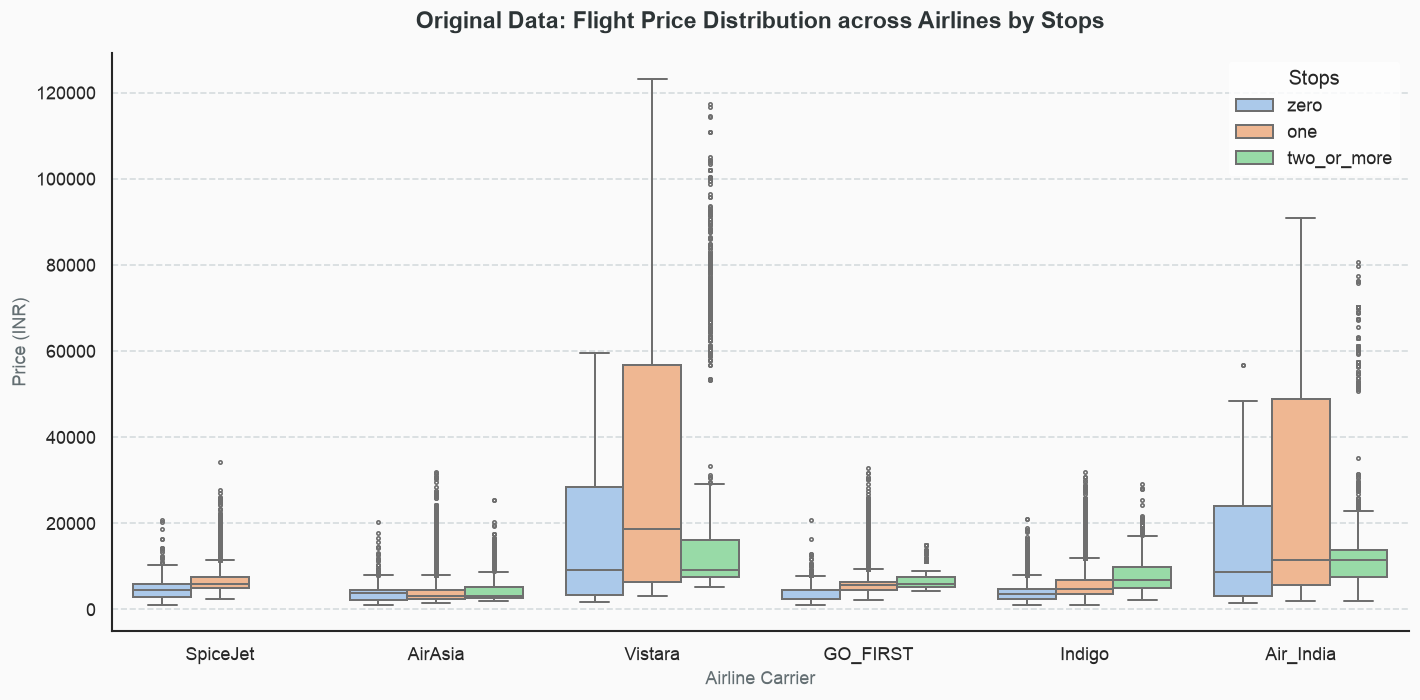

=== GENERATING AESTHETIC PLOTS FOR REGRESSION & HYPOTHESIS TESTING ===


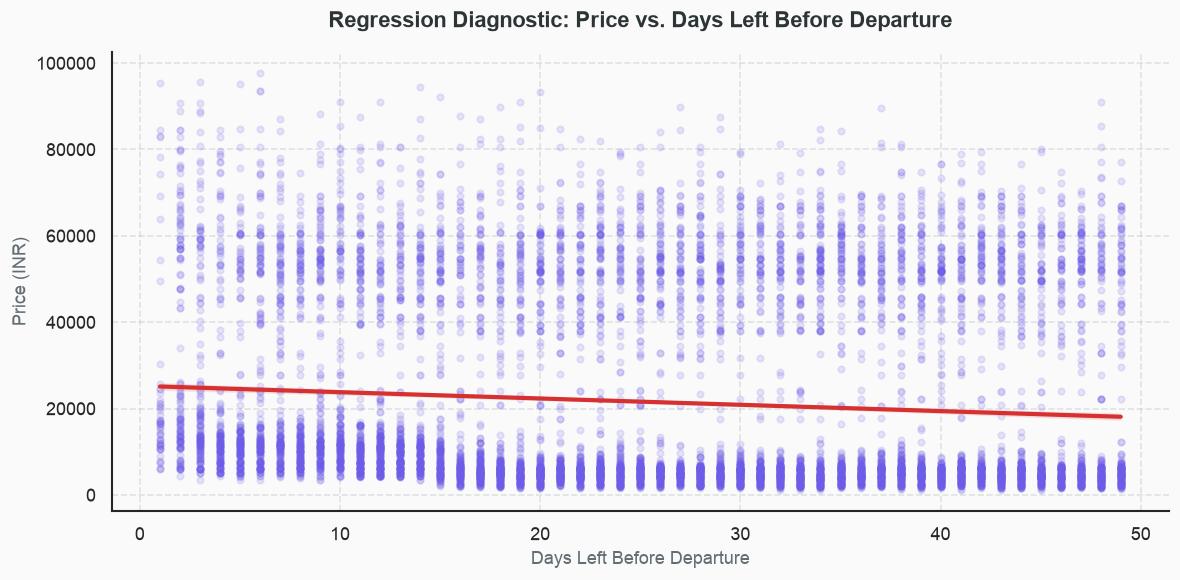

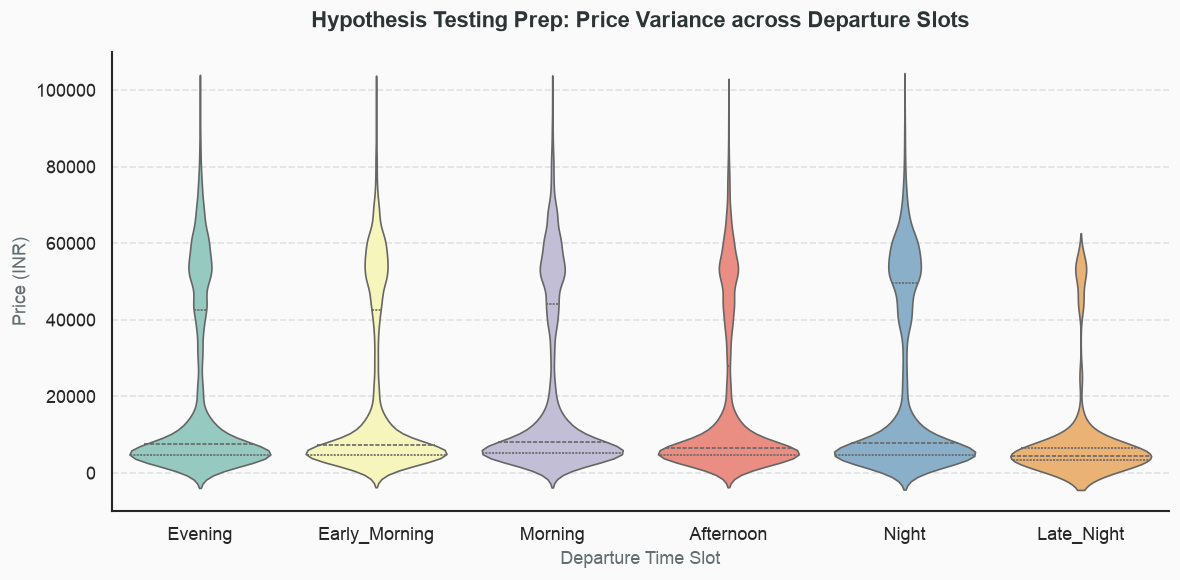

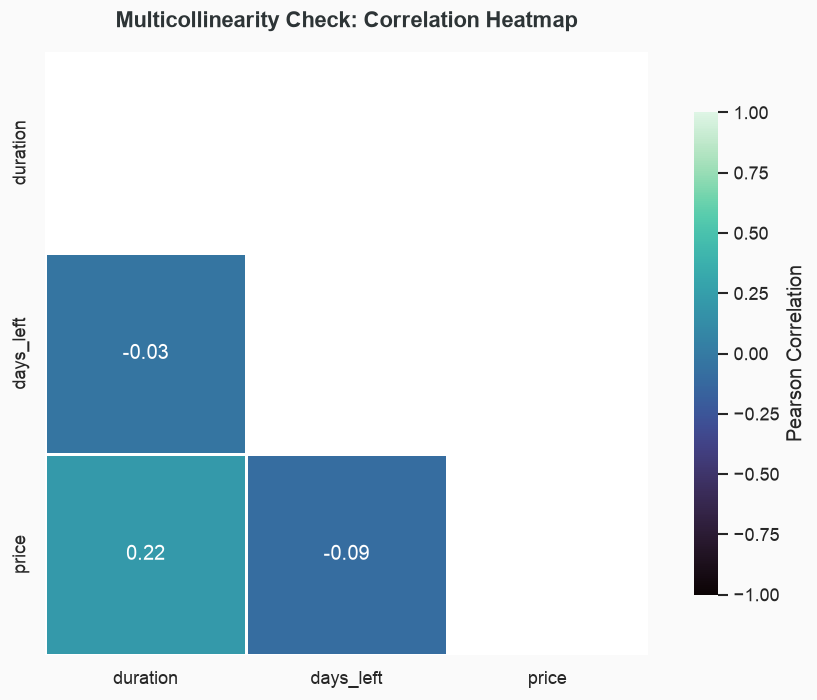

In [8]:



# Set global aesthetic styling for Seaborn/Matplotlib
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Soft aesthetic palette
custom_palette = ["#6C5CE7", "#00CEC9", "#FF7675", "#FDCB6E", "#E84393", "#00B894"]
sns.set_theme(style="white", palette=custom_palette)

# ==============================================================================
# PART 1: AESTHETIC BOXPLOT ON ORIGINAL DATA
# ==============================================================================
print("=== GENERATING AESTHETIC BOXPLOT FOR ORIGINAL DATA ===")

fig, ax = plt.subplots(figsize=(12, 6), dpi=120)
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

sns.boxplot(
    data=df_original, 
    x='airline', 
    y='price', 
    hue='stops', 
    palette="pastel",
    fliersize=2,
    linewidth=1.2,
    ax=ax
)

ax.set_title("Original Data: Flight Price Distribution across Airlines by Stops", fontsize=14, fontweight='bold', pad=15, color='#2D3436')
ax.set_xlabel("Airline Carrier", fontsize=11, fontweight='normal', color='#636E72')
ax.set_ylabel("Price (INR)", fontsize=11, fontweight='normal', color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.5, color='#B2BEC3')
plt.legend(title="Stops", frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

# ==============================================================================
# PART 2: AESTHETIC PLOTS FOR REGRESSION & HYPOTHESIS TESTING
# ==============================================================================
print("=== GENERATING AESTHETIC PLOTS FOR REGRESSION & HYPOTHESIS TESTING ===")

# ------------------------------------------------------------------------------
# PLOT 1: Minimalist Regplot - Price vs. Days Left
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

sns.regplot(
    data=df.sample(min(10000, len(df)), random_state=42), 
    x='days_left', 
    y='price', 
    scatter_kws={'alpha': 0.15, 'color': '#6C5CE7', 's': 15}, 
    line_kws={'color': '#D63031', 'linewidth': 2.5},
    # Removed lowess=True to avoid statsmodels requirement
    ax=ax
)

ax.set_title("Regression Diagnostic: Price vs. Days Left Before Departure", fontsize=13, fontweight='bold', pad=15, color='#2D3436')
ax.set_xlabel("Days Left Before Departure", fontsize=11, color='#636E72')
ax.set_ylabel("Price (INR)", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='both', linestyle='--', alpha=0.4, color='#B2BEC3')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# PLOT 2: Pastel Violin Plot - Departure Time vs. Price (ANOVA Prep)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
fig.patch.set_facecolor('#FAFAFA')
ax.set_facecolor('#FAFAFA')

sns.violinplot(
    data=df, 
    x='departure_time', 
    y='price', 
    hue='departure_time',
    legend=False,
    palette="Set3", 
    inner='quartile',
    linewidth=1,
    ax=ax
)

ax.set_title("Hypothesis Testing Prep: Price Variance across Departure Slots", fontsize=13, fontweight='bold', pad=15, color='#2D3436')
ax.set_xlabel("Departure Time Slot", fontsize=11, color='#636E72')
ax.set_ylabel("Price (INR)", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#B2BEC3')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# PLOT 3: Modern Correlation Heatmap
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6), dpi=120)
fig.patch.set_facecolor('#FAFAFA')

numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

# Mask for upper triangle for clean visual aesthetic
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap="mako", 
    vmin=-1, 
    vmax=1, 
    square=True, 
    linewidths=1.5,
    cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation'},
    ax=ax
)

ax.set_title("Multicollinearity Check: Correlation Heatmap", fontsize=13, fontweight='bold', pad=15, color='#2D3436')
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# PLOT 4: Plotly 3D Scatter with Dark/Aesthetic Template
# ------------------------------------------------------------------------------
fig_3d = px.scatter_3d(
    df.sample(min(4000, len(df)), random_state=42), 
    x='days_left',
    y='duration',
    z='price',
    color='class',
    color_discrete_map={'Economy': '#00CEC9', 'Business': '#E84393'},
    opacity=0.7,
    title="3D Feature Space: Price vs. Days Left vs. Duration",
    template="plotly_white"
)

fig_3d.update_traces(marker=dict(size=3))
fig_3d.update_layout(
    font=dict(family="DejaVu Sans", size=11, color="#2D3436"),
    margin=dict(l=10, r=10, b=10, t=40)
)
fig_3d.show()

# ------------------------------------------------------------------------------
# PLOT 5: Plotly Minimalist Residuals Plot
# ------------------------------------------------------------------------------
x = df['days_left']
y = df['price']
slope, intercept = np.polyfit(x, y, 1)
y_pred = slope * x + intercept
residuals = y - y_pred

df_res = pd.DataFrame({'fitted': y_pred, 'residuals': residuals}).sample(4000, random_state=42)

fig_residuals = px.scatter(
    df_res,
    x='fitted', 
    y='residuals',
    labels={'fitted': 'Fitted Values (Predicted Price)', 'residuals': 'Residuals'},
    title="Residuals vs. Fitted Values (Homoscedasticity Check)",
    template="plotly_white",
    color_discrete_sequence=['#6C5CE7'],
    opacity=0.35
)

fig_residuals.add_hline(y=0, line_dash="dash", line_color="#FF7675", line_width=2)
fig_residuals.update_traces(marker=dict(size=4))
fig_residuals.update_layout(
    font=dict(family="DejaVu Sans", size=11, color="#2D3436"),
    margin=dict(l=10, r=10, b=10, t=40)
)
fig_residuals.show()

=== GENERATING BAR CHART ===


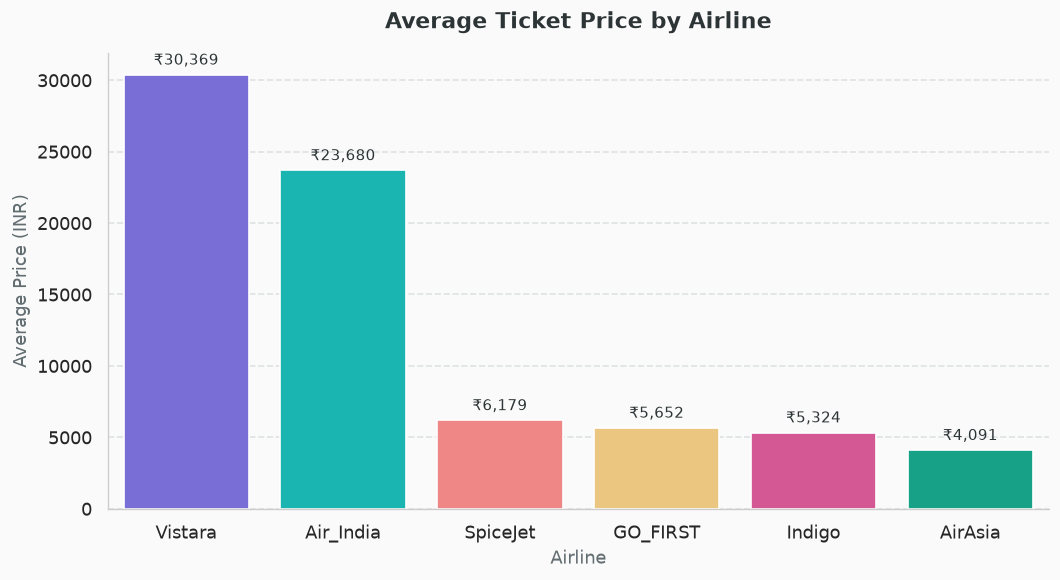

=== GENERATING PIE CHART ===


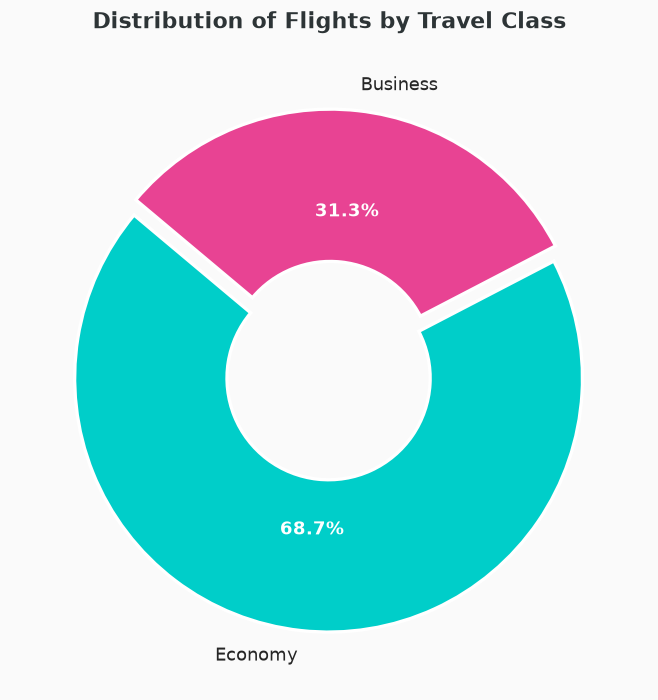

=== GENERATING LINE GRAPH ===


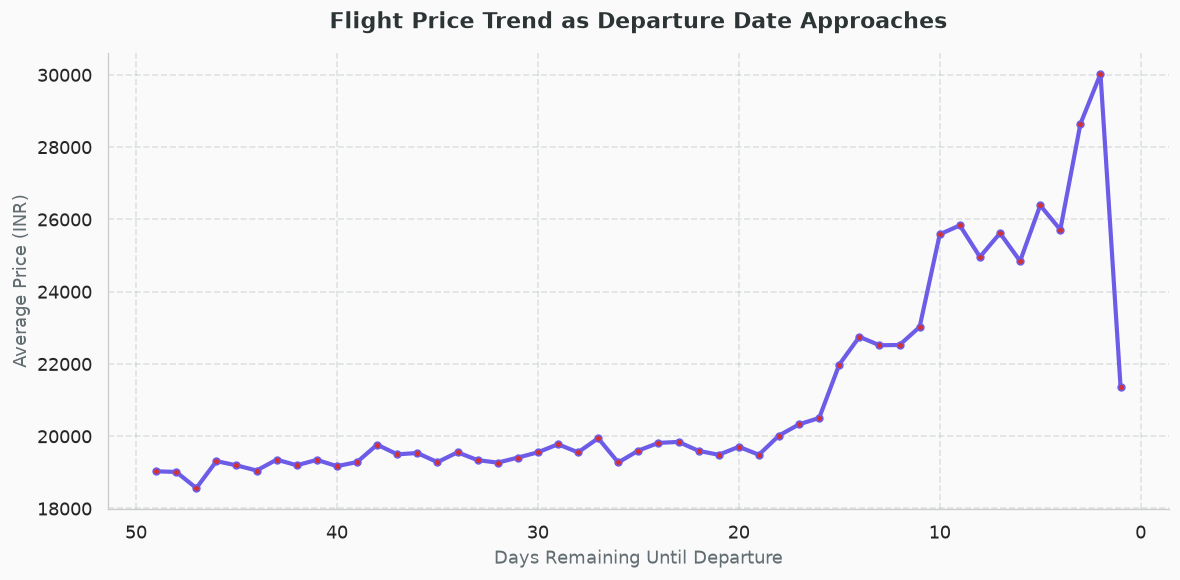

In [9]:
# Set aesthetic visual parameters
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
fig_bg = '#FAFAFA'

# Define soft color palette
colors = ["#6C5CE7", "#00CEC9", "#FF7675", "#FDCB6E", "#E84393", "#00B894"]

# ==============================================================================
# 1. SIMPLE BAR CHART: Average Ticket Price by Airline
# ==============================================================================
print("=== GENERATING BAR CHART ===")

fig, ax = plt.subplots(figsize=(9, 5), dpi=120)
fig.patch.set_facecolor(fig_bg)
ax.set_facecolor(fig_bg)

# Calculate mean price per airline
avg_prices = df.groupby('airline')['price'].mean().sort_values(ascending=False).reset_index()

sns.barplot(
    data=avg_prices, 
    x='airline', 
    y='price', 
    hue='airline',
    legend=False,
    palette=colors, 
    ax=ax
)

# Add data labels on top of each bar
for p in ax.patches:
    ax.annotate(f"₹{p.get_height():,.0f}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=9, xytext=(0, 4), 
                textcoords='offset points', color='#2D3436', fontweight='normal')

ax.set_title("Average Ticket Price by Airline", fontsize=13, fontweight='bold', pad=15, color='#2D3436')
ax.set_xlabel("Airline", fontsize=11, color='#636E72')
ax.set_ylabel("Average Price (INR)", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#B2BEC3')

plt.tight_layout()
plt.show()

# ==============================================================================
# 2. PIE CHART: Flight Proportion by Travel Class
# ==============================================================================
print("=== GENERATING PIE CHART ===")

fig, ax = plt.subplots(figsize=(6, 6), dpi=120)
fig.patch.set_facecolor(fig_bg)

class_counts = df['class'].value_counts()

wedges, texts, autotexts = ax.pie(
    class_counts, 
    labels=class_counts.index, 
    autopct='%1.1f%%',
    startangle=140,
    colors=["#00CEC9", "#E84393"],
    explode=(0.03, 0.03),
    wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2) # Donut-style clean pie
)

# Style text inside pie
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_weight('bold')
    autotext.set_fontsize(11)

ax.set_title("Distribution of Flights by Travel Class", fontsize=13, fontweight='bold', pad=15, color='#2D3436')

plt.tight_layout()
plt.show()

# ==============================================================================
# 3. LINE GRAPH: Price Trend vs. Days Left Before Departure
# ==============================================================================
print("=== GENERATING LINE GRAPH ===")

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
fig.patch.set_facecolor(fig_bg)
ax.set_facecolor(fig_bg)

# Calculate average price grouped by days left
price_trend = df.groupby('days_left')['price'].mean().reset_index()

ax.plot(
    price_trend['days_left'], 
    price_trend['price'], 
    color='#6C5CE7', 
    linewidth=2.5, 
    marker='o', 
    markersize=4, 
    markerfacecolor='#D63031'
)

# Invert X-axis so time moves closer to departure (e.g., 50 days left -> 1 day left)
ax.invert_xaxis()

ax.set_title("Flight Price Trend as Departure Date Approaches", fontsize=13, fontweight='bold', pad=15, color='#2D3436')
ax.set_xlabel("Days Remaining Until Departure", fontsize=11, color='#636E72')
ax.set_ylabel("Average Price (INR)", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='both', linestyle='--', alpha=0.4, color='#B2BEC3')

plt.tight_layout()
plt.show()

=== GENERATING QQ PLOTS ===


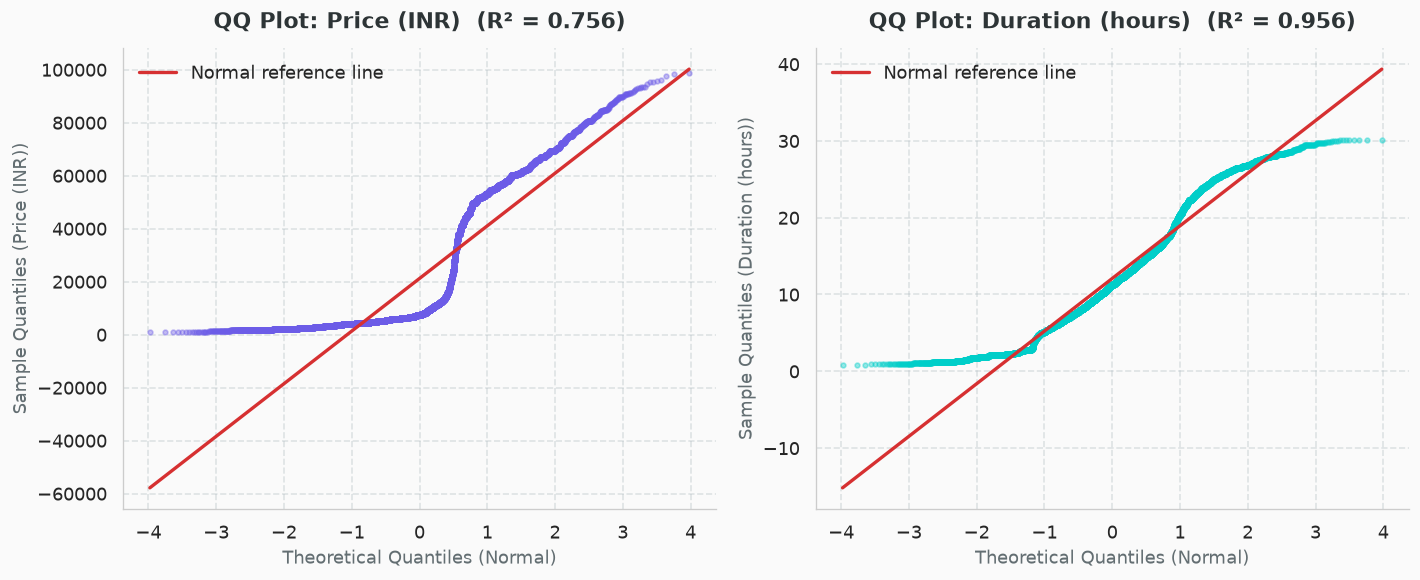

=== GENERATING KDE PLOTS ===


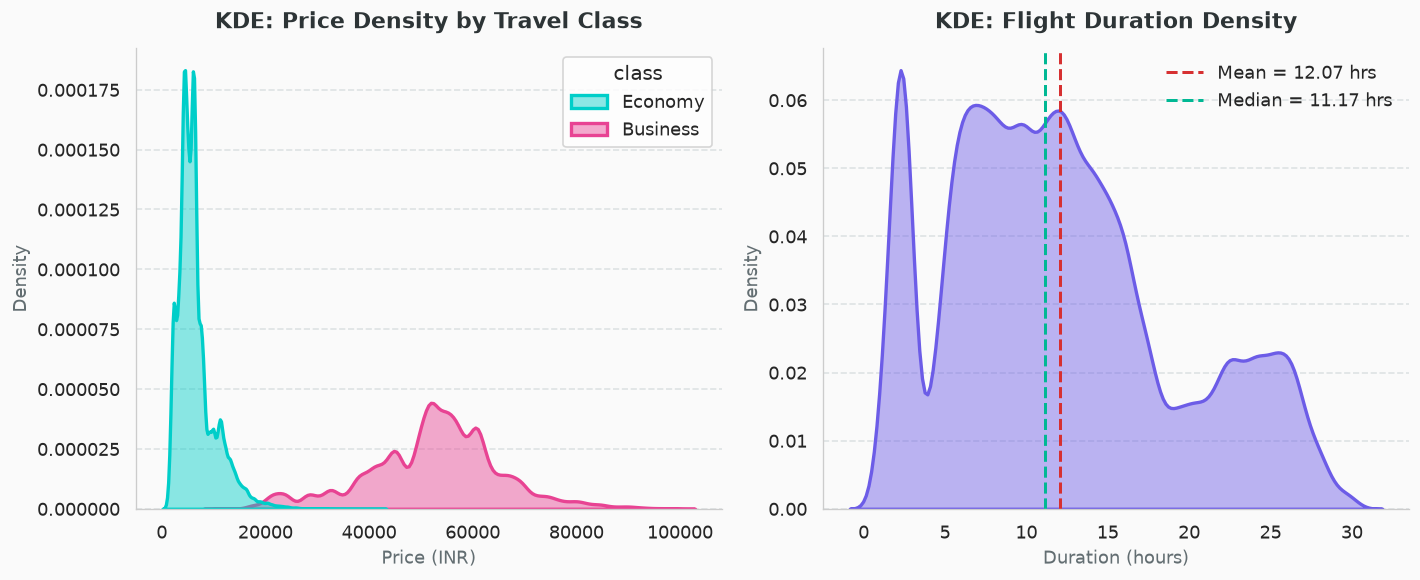

In [10]:
# ==============================================================================
# PART 3: QQ PLOTS (NORMALITY CHECK) AND KDE PLOTS (DISTRIBUTION SHAPE)
# ==============================================================================
from scipy import stats

fig_bg = '#FAFAFA'

# ------------------------------------------------------------------------------
# PLOT 1: QQ Plots - Price and Duration vs. Theoretical Normal Distribution
# Points on the red line = normally distributed; curved tails = skew / heavy tails
# ------------------------------------------------------------------------------
print("=== GENERATING QQ PLOTS ===")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)
fig.patch.set_facecolor(fig_bg)

qq_features = [('price', '#6C5CE7', 'Price (INR)'), ('duration', '#00CEC9', 'Duration (hours)')]

for ax, (col, color, label) in zip(axes, qq_features):
    ax.set_facecolor(fig_bg)

    # Sample for faster plotting; the QQ shape is preserved
    sample = df[col].sample(min(20000, len(df)), random_state=42)
    (theoretical_q, ordered_vals), (qq_slope, qq_intercept, qq_r) = stats.probplot(sample, dist='norm')

    ax.scatter(theoretical_q, ordered_vals, s=8, alpha=0.4, color=color)
    ax.plot(theoretical_q, qq_slope * theoretical_q + qq_intercept, color='#D63031', linewidth=2, label='Normal reference line')

    ax.set_title(f"QQ Plot: {label}  (R\u00b2 = {qq_r**2:.3f})", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
    ax.set_xlabel("Theoretical Quantiles (Normal)", fontsize=11, color='#636E72')
    ax.set_ylabel(f"Sample Quantiles ({label})", fontsize=11, color='#636E72')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='both', linestyle='--', alpha=0.4, color='#B2BEC3')
    ax.legend(frameon=False, loc='upper left')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# PLOT 2: KDE Plots - Price by Travel Class and Duration
# ------------------------------------------------------------------------------
print("=== GENERATING KDE PLOTS ===")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)
fig.patch.set_facecolor(fig_bg)

# KDE 1: Price density split by travel class
ax = axes[0]
ax.set_facecolor(fig_bg)
sns.kdeplot(
    data=df,
    x='price',
    hue='class',
    fill=True,
    common_norm=False,
    palette={'Economy': '#00CEC9', 'Business': '#E84393'},
    alpha=0.45,
    linewidth=2,
    ax=ax
)
ax.set_title("KDE: Price Density by Travel Class", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Price (INR)", fontsize=11, color='#636E72')
ax.set_ylabel("Density", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#B2BEC3')

# KDE 2: Flight duration density
ax = axes[1]
ax.set_facecolor(fig_bg)
sns.kdeplot(
    data=df,
    x='duration',
    fill=True,
    color='#6C5CE7',
    alpha=0.45,
    linewidth=2,
    ax=ax
)
ax.axvline(df['duration'].mean(), color='#D63031', linestyle='--', linewidth=1.8, label=f"Mean = {df['duration'].mean():.2f} hrs")
ax.axvline(df['duration'].median(), color='#00B894', linestyle='--', linewidth=1.8, label=f"Median = {df['duration'].median():.2f} hrs")
ax.set_title("KDE: Flight Duration Density", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Duration (hours)", fontsize=11, color='#636E72')
ax.set_ylabel("Density", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4, color='#B2BEC3')
ax.legend(frameon=False)

plt.tight_layout()
plt.show()


## 7. Dropping the high-cardinality `flight` column

=== GENERATING JUSTIFICATION PLOT FOR DROPPING 'flight' ===


Unique flight codes                          : 1,561
One-Hot columns 'flight' alone would create   : 1,561
One-Hot columns of all other categoricals     : 35
Flight-code prefixes mapping to >1 airline    : 0 (0 = prefix fully determined by 'airline')


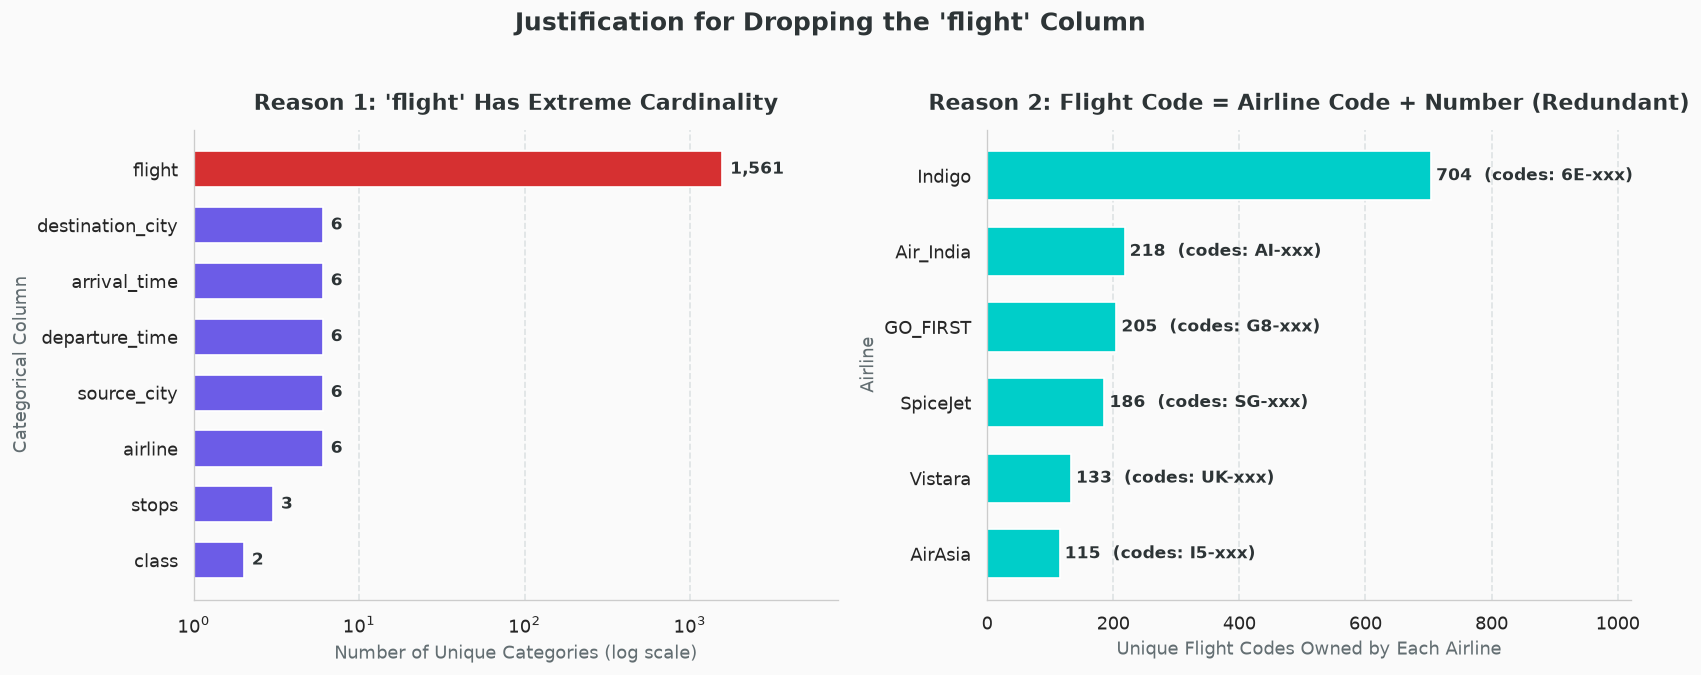

In [11]:
# ==============================================================================
# JUSTIFICATION PLOT: WHY THE 'flight' COLUMN IS DROPPED (and 'stops' is retained)
# ==============================================================================
print("=== GENERATING JUSTIFICATION PLOT FOR DROPPING 'flight' ===")

fig_bg = '#FAFAFA'

# Categorical columns of the original dataset that are still present in df
cat_cols = [c for c in df_original.columns if c in df.columns and not pd.api.types.is_numeric_dtype(df[c])]
cardinality = df[cat_cols].nunique().sort_values()

# The flight code is "<airline code>-<number>", e.g. 'UK-995' -> prefix 'UK'
flight_prefix = df['flight'].str.split('-').str[0]
airlines_per_prefix = df.groupby(flight_prefix)['airline'].nunique()
flights_per_airline = df.groupby('airline')['flight'].nunique().sort_values()
prefix_of_airline = df.assign(prefix=flight_prefix).groupby('airline')['prefix'].agg(lambda s: s.mode()[0])

print(f"Unique flight codes                          : {df['flight'].nunique():,}")
print(f"One-Hot columns 'flight' alone would create   : {df['flight'].nunique():,}")
print(f"One-Hot columns of all other categoricals     : {int(cardinality.drop('flight').sum())}")
print(f"Flight-code prefixes mapping to >1 airline    : {(airlines_per_prefix > 1).sum()} (0 = prefix fully determined by 'airline')")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120, gridspec_kw={'width_ratios': [1, 1]})
fig.patch.set_facecolor(fig_bg)

# ---- Panel 1: cardinality of every categorical column ----
ax = axes[0]
ax.set_facecolor(fig_bg)
bar_colors = ['#D63031' if c == 'flight' else '#6C5CE7' for c in cardinality.index]
bars = ax.barh(cardinality.index, cardinality.values, color=bar_colors, edgecolor='white', height=0.65)
ax.set_xscale('log')
for bar, val in zip(bars, cardinality.values):
    ax.text(val * 1.12, bar.get_y() + bar.get_height() / 2, f"{val:,}", va='center', fontsize=10,
            fontweight='bold', color='#2D3436')
ax.set_xlim(1, cardinality.max() * 5)
ax.set_title("Reason 1: 'flight' Has Extreme Cardinality", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Number of Unique Categories (log scale)", fontsize=11, color='#636E72')
ax.set_ylabel("Categorical Column", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.4, color='#B2BEC3')

# ---- Panel 2: every flight code belongs to exactly one airline -> redundant with 'airline' ----
ax = axes[1]
ax.set_facecolor(fig_bg)
ax.barh(flights_per_airline.index, flights_per_airline.values, color='#00CEC9', edgecolor='white', height=0.65)
for i, (airline, val) in enumerate(flights_per_airline.items()):
    ax.text(val + 8, i, f"{val}  (codes: {prefix_of_airline[airline]}-xxx)", va='center', fontsize=10,
            fontweight='bold', color='#2D3436')
ax.set_xlim(0, flights_per_airline.max() * 1.45)
ax.set_title("Reason 2: Flight Code = Airline Code + Number (Redundant)", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Unique Flight Codes Owned by Each Airline", fontsize=11, color='#636E72')
ax.set_ylabel("Airline", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.4, color='#B2BEC3')

fig.suptitle("Justification for Dropping the 'flight' Column", fontsize=15, fontweight='bold', color='#2D3436', y=1.02)
plt.tight_layout()
plt.show()


In [12]:
# 1. Print current columns before dropping
print("Columns before dropping:", list(df.columns))

# 2. Drop the 'flight' column
if 'flight' in df.columns:
    df = df.drop(columns=['flight'])
    print("-> Successfully dropped the 'flight' column.")
else:
    print("-> The column 'flight' was not found in the DataFrame.")

# 3. Verify updated columns
print("Columns after dropping:", list(df.columns))

Columns before dropping: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price', 'route']
-> Successfully dropped the 'flight' column.
Columns after dropping: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price', 'route']


## 8. Hypothesis tests

In [13]:
# ==============================================================================
# HYPOTHESIS TESTS (Section 5 of the report)
# The tests live in hypothesis_tests.py so the notebook and the report use the same code.
# For every test this prints H0/H1, alpha, tail, the smallest meaningful effect, the
# statistic, df, p-value, decision, the estimate with a 95% CI, and the alternative
# tests we compared it against.
# ==============================================================================
from hypothesis_tests import clean, run_all

# Sanity check: the standalone cleaning pipeline gives the same rows as this notebook
assert len(clean(pd.read_csv("Clean_Dataset.csv"))) == len(df)

run_all(df)

Rows tested: 297,920; alpha = 0.05; Bonferroni alpha = 0.01

TEST 1: Last-day price drop  |  Welch two-sample t-test, right-tailed
H0: mu(day 2) - mu(day 1) <= 0    H1: mu(day 2) - mu(day 1) > 0
alpha = 0.05, smallest meaningful difference = Rs 1,000
n(day 2) = 3,942, n(day 1) = 1,884; means = 30,024 vs 21,351
SD day 2 = 24,138, SD day 1 = 18,841
Welch t = 14.956, df = 4,633.5, p = 9.971e-50 -> Reject H0
Estimate = Rs 8,672, 95% CI [7,535, 9,809], Cohen's d = 0.384
Alternatives:
  Student t (pooled var): t = 13.724, df = 5,824, p = 1.652e-42
  Mann-Whitney U: U = 4,317,415, p = 4.203e-24, P(day2 > day1) = 0.581
  Medians: day 2 = 17,854, day 1 = 15,078


  Permutation test (10,000 shuffles): p = 1.00e-04
  Bootstrap 95% CI for mean difference: [7,542, 9,759]
  Levene (equal variances?): p = 9.56e-51

TEST 2: Late (<= 20 d) vs early (> 20 d) mean fare  |  two-sample Z, two-tailed
H0: mu(late) - mu(early) = 0    H1: mu(late) - mu(early) != 0
alpha = 0.05, smallest meaningful difference = Rs 500
n(late) = 112,403, n(early) = 185,517; means = 23,327 vs 19,402
Z = 46.085 (df not applicable; Welch df = 239,268), p = 0.000e+00 -> Reject H0
Estimate = Rs 3,924, 95% CI [3,757, 4,091], Cohen's d = 0.174, relative = +20.2%
Alternatives:
  Welch t: t = 46.085, df = 239,268, p = 0.000e+00
  Mann-Whitney U: p = 0.000e+00, P(late > early) = 0.652; medians 11,511 vs 6,067


  Within Economy: diff = Rs 4,069 [4,036, 4,102], Z = 239.61, relative = +81.2%
  Within Business: diff = Rs 1,846 [1,673, 2,018], Z = 20.96, relative = +3.6%
  Sensitivity, late = last week (<= 7 d): diff = Rs 6,912, Z = 49.40

TEST 3: Late vs early fare variance  |  F-test, right-tailed
H0: var(late) / var(early) <= 1    H1: var(late) / var(early) > 1
alpha = 0.05, smallest meaningful effect = SD ratio 1.10 (variance ratio 1.21)
SD late = 22,430, SD early = 22,690
F = 0.9772, df = (112,402, 185,516), p = 1.0000 -> Fail to reject H0
Estimate = variance ratio 0.9772, 95% CI [0.9670, 0.9875]
Alternatives:
  Bartlett: stat = 18.60, p = 1.613e-05
  Levene (mean-centred): W = 134.21, df = (1, 297,918), p = 4.980e-31
  Brown-Forsythe (median-centred): W = 169.89, p = 8.012e-39
  Mean |x - median|: late = 16,328, early = 15,309
  Within Economy: SD 4,425 vs 2,030, F = 4.752 [4.692, 4.813], p = 0.00e+00, BF p = 0.00e+00
  Within Business: SD 13,552 vs 12,315, F = 1.211 [1.189, 1.234], p = 2.0

## 9. Plots for the hypothesis tests

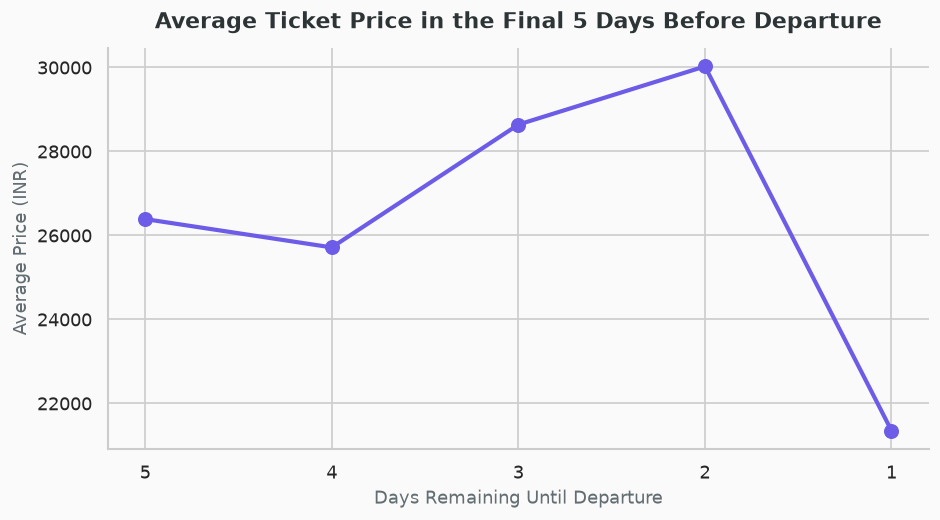

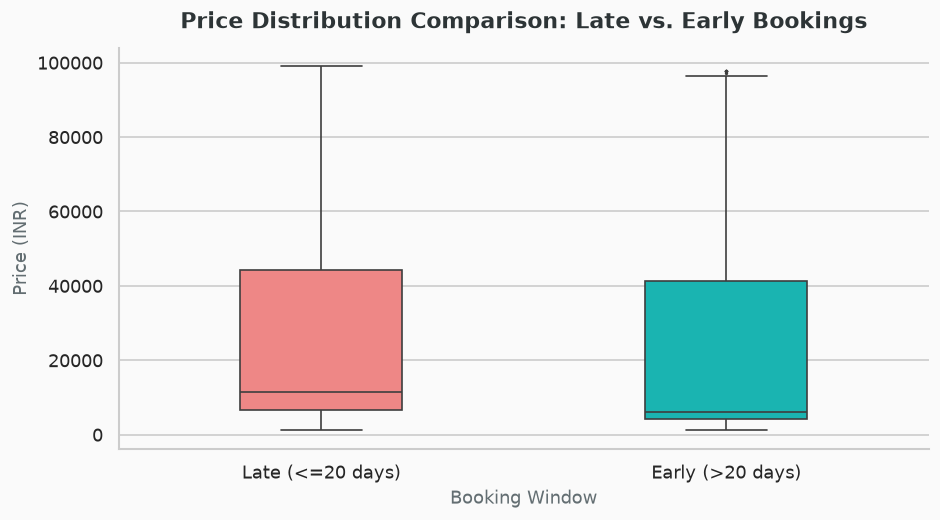

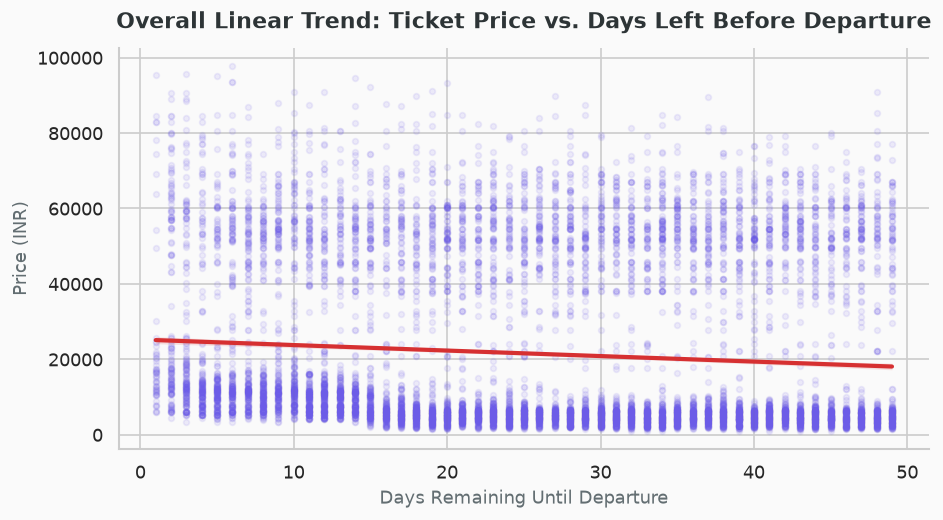

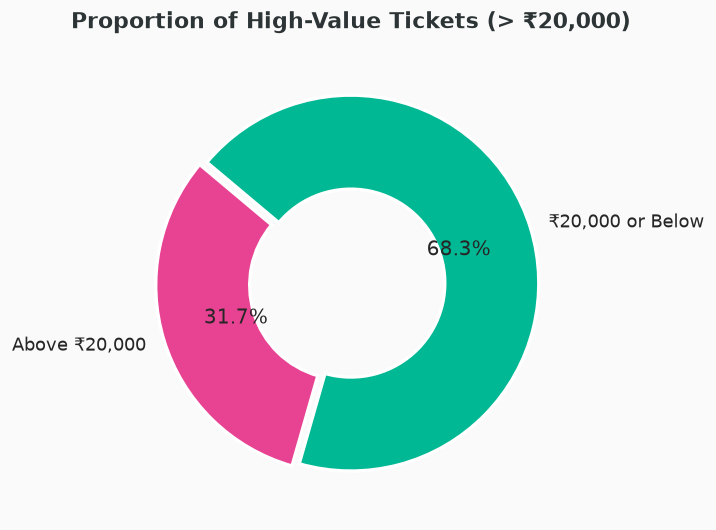

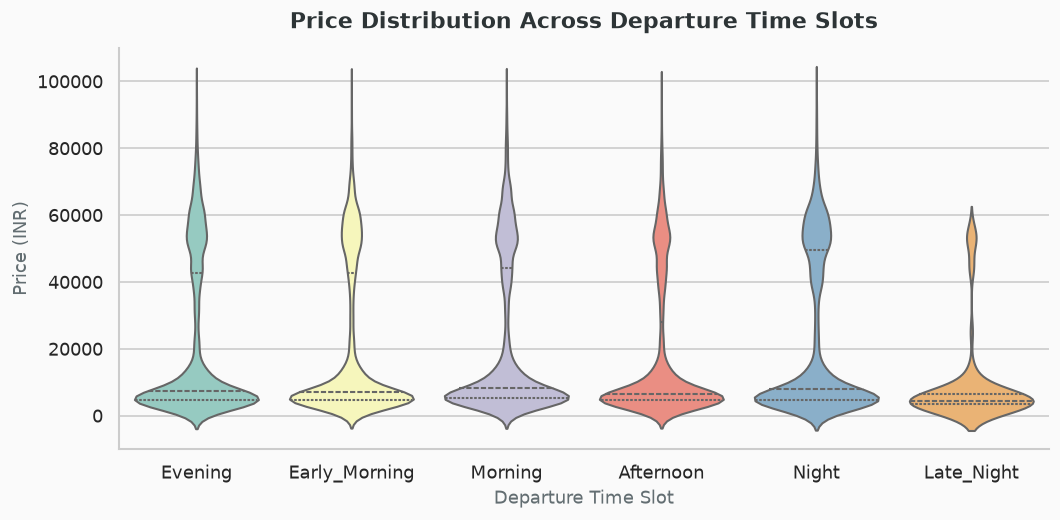

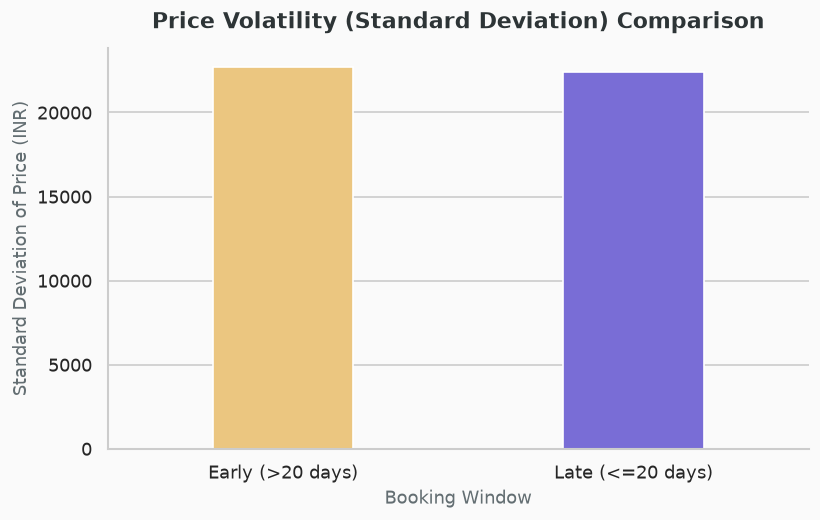

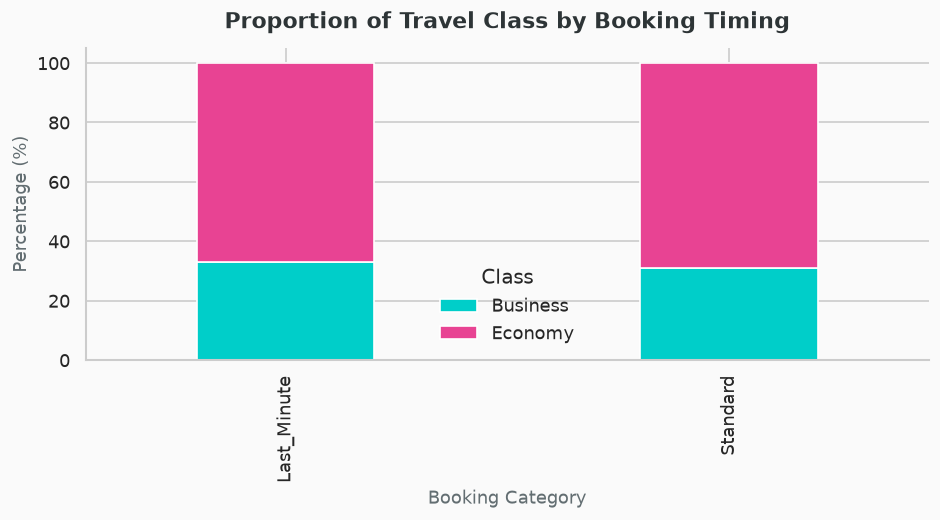

In [14]:
# Global aesthetic styling
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
fig_bg = '#FAFAFA'

sns.set_theme(style="whitegrid", font="DejaVu Sans")

# Create temporary columns for categorical aggregation if missing
if 'booking_category' not in df.columns:
    df['booking_category'] = np.where(df['days_left'] <= 7, 'Last_Minute', 'Standard')

df['booking_window'] = np.where(df['days_left'] <= 20, 'Late (<=20 days)', 'Early (>20 days)')

# ==============================================================================
# PLOT 1: PRICE TREND FOR FINAL DAYS (Visualizing Test 1)
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
fig.patch.set_facecolor(fig_bg)
ax.set_facecolor(fig_bg)

final_days_df = df[df['days_left'] <= 5].groupby('days_left')['price'].mean().reset_index()

ax.plot(final_days_df['days_left'], final_days_df['price'], marker='o', color='#6C5CE7', linewidth=2.5, markersize=8)
ax.set_xticks([1, 2, 3, 4, 5])
ax.invert_xaxis()

ax.set_title("Average Ticket Price in the Final 5 Days Before Departure", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Days Remaining Until Departure", fontsize=11, color='#636E72')
ax.set_ylabel("Average Price (INR)", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 2: PRICE DISTRIBUTION BY BOOKING WINDOW (Visualizing Test 2)
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
fig.patch.set_facecolor(fig_bg)
ax.set_facecolor(fig_bg)

sns.boxplot(data=df, x='booking_window', y='price', hue='booking_window', legend=False, palette=['#FF7675', '#00CEC9'], ax=ax, width=0.4, fliersize=1)

ax.set_title("Price Distribution Comparison: Late vs. Early Bookings", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Booking Window", fontsize=11, color='#636E72')
ax.set_ylabel("Price (INR)", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 3: LINEAR TREND OF PRICE VS DAYS LEFT (Visualizing Test 3)
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
fig.patch.set_facecolor(fig_bg)
ax.set_facecolor(fig_bg)

sns.regplot(
    data=df.sample(min(10000, len(df)), random_state=42), 
    x='days_left', y='price',
    scatter_kws={'alpha': 0.1, 'color': '#6C5CE7', 's': 12},
    line_kws={'color': '#D63031', 'linewidth': 2.5},
    ax=ax
)

ax.set_title("Overall Linear Trend: Ticket Price vs. Days Left Before Departure", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Days Remaining Until Departure", fontsize=11, color='#636E72')
ax.set_ylabel("Price (INR)", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 4: HIGH PRICE TICKET PROPORTION (Visualizing Test 4)
# ==============================================================================
fig, ax = plt.subplots(figsize=(6, 6), dpi=120)
fig.patch.set_facecolor(fig_bg)

high_price_counts = pd.Series({
    'Above ₹20,000': (df['price'] > 20000).sum(),
    '₹20,000 or Below': (df['price'] <= 20000).sum()
})

ax.pie(
    high_price_counts, 
    labels=high_price_counts.index, 
    autopct='%1.1f%%',
    startangle=140,
    colors=['#E84393', '#00B894'],
    explode=(0.04, 0),
    wedgeprops=dict(width=0.5, edgecolor='white', linewidth=2)
)

ax.set_title("Proportion of High-Value Tickets (> ₹20,000)", fontsize=13, fontweight='bold', pad=12, color='#2D3436')

plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 5: PRICE VARIATION BY DEPARTURE TIME (Visualizing Test 5)
# ==============================================================================
fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)
fig.patch.set_facecolor(fig_bg)
ax.set_facecolor(fig_bg)

sns.violinplot(data=df, x='departure_time', y='price', hue='departure_time', legend=False, palette='Set3', inner='quartile', ax=ax)

ax.set_title("Price Distribution Across Departure Time Slots", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Departure Time Slot", fontsize=11, color='#636E72')
ax.set_ylabel("Price (INR)", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 6: PRICE VOLATILITY / VARIANCE COMPARISON (Visualizing Test 6)
# ==============================================================================
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
fig.patch.set_facecolor(fig_bg)
ax.set_facecolor(fig_bg)

std_data = df.groupby('booking_window')['price'].std().reset_index()

sns.barplot(data=std_data, x='booking_window', y='price', hue='booking_window', legend=False, palette=['#FDCB6E', '#6C5CE7'], ax=ax, width=0.4)

ax.set_title("Price Volatility (Standard Deviation) Comparison", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Booking Window", fontsize=11, color='#636E72')
ax.set_ylabel("Standard Deviation of Price (INR)", fontsize=11, color='#636E72')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 7: CLASS BREAKDOWN BY BOOKING TIMING (Visualizing Test 7)
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
fig.patch.set_facecolor(fig_bg)
ax.set_facecolor(fig_bg)

contingency = pd.crosstab(df['booking_category'], df['class'], normalize='index') * 100
contingency.plot(kind='bar', stacked=True, color=['#00CEC9', '#E84393'], ax=ax, edgecolor='white', width=0.4)

ax.set_title("Proportion of Travel Class by Booking Timing", fontsize=13, fontweight='bold', pad=12, color='#2D3436')
ax.set_xlabel("Booking Category", fontsize=11, color='#636E72')
ax.set_ylabel("Percentage (%)", fontsize=11, color='#636E72')
ax.legend(title="Class", frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()